<a href="https://colab.research.google.com/github/mishrasatyam9720-debug/model_from_scrartch/blob/main/Copy_of_4_10_assignment_multiclass_pytorch_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 4 Assignment — Multi-Class Classification in PyTorch and Keras

Every network in this course so far has been **binary**: one output neuron, a sigmoid, and binary cross-entropy. Section 3 by hand, Section 4 with frameworks — always two classes.

This assignment moves to **three classes**. That one change forces four things you have not typed before:

- **3 output neurons** instead of 1
- **integer labels** (`0`, `1`, `2`) instead of a float column of 0s and 1s
- **`CrossEntropyLoss`** instead of `BCELoss` — and it takes **raw logits**, with no activation on the output layer
- **`argmax`** to turn 3 numbers into a predicted class, instead of thresholding at 0.5

You will build the same network twice — PyTorch, then Keras — and run one experiment that shows what happens if you get the softmax convention wrong.

**How this works:** each task has a code cell with `# TODO` lines. Expected output is above the cell. Shapes are exact; losses and accuracies are given as ranges, since framework initialization is random.

Around 45 minutes.

## 0. Setup

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
tf.random.set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| device:", device)
print("TensorFlow:", tf.__version__)

PyTorch: 2.11.0+cpu | device: cpu
TensorFlow: 2.21.0


---
# Part 1 — Three-Class Data

### Task 1 — Load and inspect

Use `make_blobs` with `n_samples=600`, `centers=3`, `n_features=2`, `cluster_std=3.0`, `random_state=42`.

Print `X.shape`, `y.shape`, `y.dtype`, the unique values in `y`, and the count per class. Then scatter-plot the data coloured by `y`.

**Expected:** `X (600, 2)`, `y (600,)`, dtype `int64`, unique values `[0 1 2]`, 200 samples per class.

Two things to notice. `y` is **one-dimensional** — no `reshape(-1, 1)` this time. And it holds **integers naming a class**, not floats. Both differences matter in Task 3.

The clusters overlap around the edges on purpose. A dataset you can classify perfectly teaches you nothing about validation.

X shape: (600, 2)
y shape: (600,)
y dtype: int64
Unique values: [0 1 2]
Counts per class: [200 200 200]


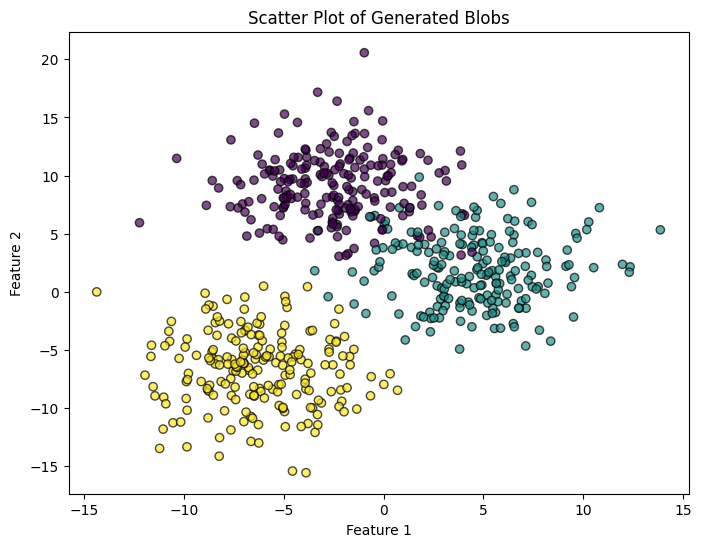

In [8]:
# TODO: create X, y with make_blobs
X, y = make_blobs(n_samples=600, centers=3, n_features=2, cluster_std=3.0, random_state=42)

# TODO: print shape, dtype, unique values, per-class counts
unique, counts = np.unique(y, return_counts=True)
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"y dtype: {y.dtype}")
print(f"Unique values: {unique}")
print(f"Counts per class: {counts}")

# TODO: scatter plot coloured by y
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.7)
plt.title("Scatter Plot of Generated Blobs")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### Task 2 — Split

Same two-step split as always: 20% test, then 12.5% of the remainder for validation, `random_state=42` both times.

**Expected:** Train `420`, Val `60`, Test `120`

In [11]:
# TODO: two-step split, print the three sizes
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, random_state=42)

print("Train size:", len(X_train))
print("Val size:", len(X_val))
print("Test size:", len(X_test))

Train size: 420
Val size: 60
Test size: 120


---
# Part 2 — PyTorch

### Task 3 — Tensors, with two different dtypes

This is the part people get wrong.

- `X` becomes **`torch.float32`** — as always
- `y` becomes **`torch.long`** (64-bit integer), and stays 1-D

Convert all six arrays and print the shape and dtype of `X_train_t` and `y_train_t`.

**Expected:** `X_train_t torch.Size([420, 2]) torch.float32` and `y_train_t torch.Size([420]) torch.int64`

`CrossEntropyLoss` treats each label as an **index** telling it which of the 3 outputs should have been the largest. An index has to be an integer. Hand it floats and it raises an error immediately — which is the good case. The bad case is a label shaped `(420, 1)` instead of `(420,)`, which fails in a much less obvious way.

In [13]:
device = "cuda" if torch.cuda.is_available() else "cpu"

def to_X(a):
    return torch.tensor(a, dtype=torch.float32, device=device)

def to_y(a):
    return torch.tensor(a, dtype=torch.long, device=device)

# TODO: convert all six arrays
X_train_t = to_X(X_train)
X_val_t = to_X(X_val)
X_test_t = to_X(X_test)

y_train_t = to_y(y_train)
y_val_t = to_y(y_val)
y_test_t = to_y(y_test)

# TODO: print shape and dtype of X_train_t and y_train_t
print("X_train_t", X_train_t.shape, X_train_t.dtype)
print("y_train_t", y_train_t.shape, y_train_t.dtype)

X_train_t torch.Size([420, 2]) torch.float32
y_train_t torch.Size([420]) torch.int64


### Task 4 — The model: 2 → 8 → 3

Write a `Net` class with:

- `fc1 = nn.Linear(2, 8)`, with **ReLU** after it
- `fc2 = nn.Linear(8, 3)`, with **no activation at all**

Instantiate, move to `device`, print it. Then run one forward pass on `X_train_t` and print the output shape and the first row.

**Expected:** output shape `torch.Size([420, 3])`, and the first row is three unconstrained numbers — some negative, not summing to 1.

Those raw numbers are called **logits**. Leaving the output bare looks wrong after all that sigmoid, but it is deliberate: `nn.CrossEntropyLoss` applies log-softmax internally. Add your own softmax and it gets applied twice — which you will measure in Task 8.

The hidden layer uses ReLU here rather than sigmoid, which is what lecture 3.2 called the default for hidden layers.

In [18]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 8)
        self.fc2 = nn.Linear(8, 3)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# TODO: instantiate, move to device, print
model = Net().to(device)
print(model)

# TODO: one forward pass, print output shape and the first row
with torch.no_grad():
    output = model(X_train_t)
print("Output shape:", output.shape)
print("First row:", output[0])

Net(
  (fc1): Linear(in_features=2, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=3, bias=True)
)
Output shape: torch.Size([420, 3])
First row: tensor([-1.7110, -2.3615, -0.6452])


### Task 5 — Loss and optimizer

`criterion = nn.CrossEntropyLoss()` and SGD over `model.parameters()` with `lr=0.1`.

Compute the loss on your untrained forward pass and print it.

**Expected:** about `1.0` – `1.2`

An untrained 3-class model spreads its guess evenly, one-third to each class, so the loss should start near `-log(1/3) = 1.0986`. On a binary problem that starting point was `0.693`. If your first loss is wildly off, something upstream is wrong — check it now rather than after 300 epochs.

In [22]:
# TODO: criterion and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

# TODO: print the loss on the untrained output
loss = criterion(output, y_train_t)
print("Untrained loss:", loss.item())

Untrained loss: 0.6852189302444458


### Task 6 — Training loop

300 epochs — far fewer than before, because ReLU and this optimizer converge much faster than the all-sigmoid networks.

Each epoch: `model.train()` → `zero_grad` → forward → loss → `backward` → `step` → record. Then `model.eval()` under `no_grad()` for the validation loss.

Print train and val loss every 50 epochs.

**Expected:** starts near `1.1`, ends around `0.10 – 0.15`.

In [25]:
epochs = 300
train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    y_pred = model(X_train_t)
    loss = criterion(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    # Validation loss under no_grad
    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val_t), y_val_t)
        val_losses.append(val_loss.item())

    # Print every 50 epochs
    if (epoch + 1) % 50 == 0:
        print(f"epoch {epoch+1:4d} | train {loss.item():.4f} | val {val_loss.item():.4f}")

epoch   50 | train 0.1532 | val 0.1175
epoch  100 | train 0.1359 | val 0.1198
epoch  150 | train 0.1257 | val 0.1201
epoch  200 | train 0.1197 | val 0.1150
epoch  250 | train 0.1160 | val 0.1128
epoch  300 | train 0.1133 | val 0.1121


### Task 7 — Evaluate

1. Plot the two loss curves.
2. Accuracy on train, val and test. Predictions come from **`outputs.argmax(dim=1)`** — the index of the largest logit — compared directly against the integer labels.
3. Plot the decision boundary. With 3 classes, predict `argmax` over the grid and draw it with `plt.contourf(xx, yy, zz, alpha=0.3)` — you'll get three coloured regions instead of two.

**Expected:** test accuracy around `95 – 98%`, and a plot split into three regions meeting near the middle.

No `> 0.5` anywhere. Thresholding only ever made sense with one output; with three you take whichever is largest. And notice you never needed softmax to do it — the largest logit is the largest probability, since softmax preserves order.

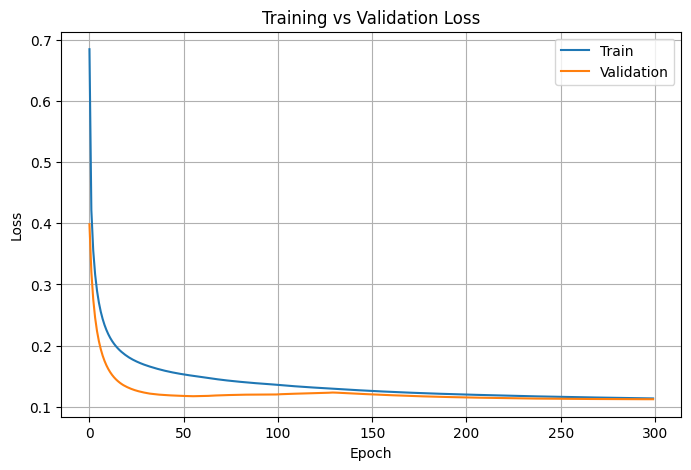

Train accuracy: 95.95%
Val   accuracy: 95.00%
Test  accuracy: 97.50%


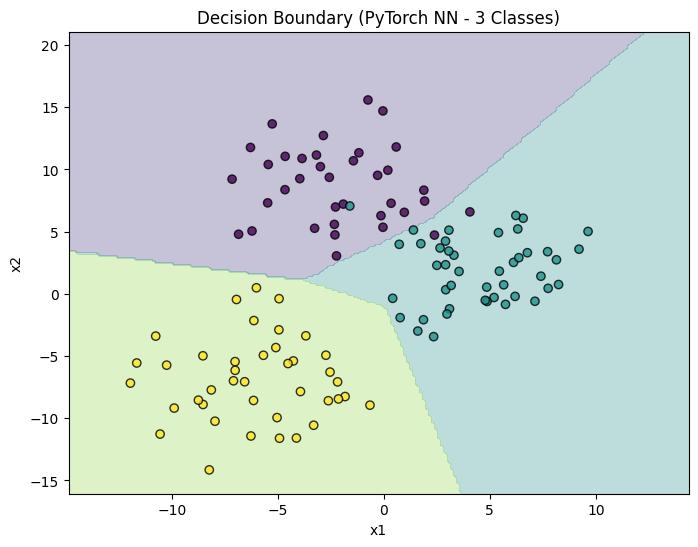

In [28]:
# TODO: plot the loss curves
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train')
plt.plot(val_losses, label='Validation')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# TODO: accuracy on all three splits using argmax(dim=1)
model.eval()
with torch.no_grad():
    for name, Xs, ys in [("Train", X_train_t, y_train_t),
                         ("Val",   X_val_t,   y_val_t),
                         ("Test",  X_test_t,  y_test_t)]:
        preds = model(Xs).argmax(dim=1)
        acc = (preds == ys).float().mean() * 100
        print(f"{name:5s} accuracy: {acc:.2f}%")

# TODO: decision boundary with three regions
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()],
                    dtype=torch.float32, device=device)

model.eval()
with torch.no_grad():
    zz = model(grid).argmax(dim=1).cpu().numpy().reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], cmap='viridis', alpha=0.3)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(),
            cmap='viridis', edgecolor='k', alpha=0.8)
plt.title("Decision Boundary (PyTorch NN - 3 Classes)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

### Task 8 — The softmax mistake

Now break it on purpose, so you know what it looks like.

Copy your model but add `torch.softmax(x, dim=1)` to the end of `forward`. Keep `CrossEntropyLoss`. Retrain with identical settings and print the final train loss and test accuracy.

**Expected:** final train loss stuck around `0.55 – 0.65` — roughly five times worse than Task 6 — while test accuracy only drops a couple of points, to around `94 – 96%`.

Read that result carefully, because it is the whole reason this task exists. The model still mostly works. Nothing crashes, nothing warns you, and the accuracy looks almost fine — so this bug ships. The only visible symptom is a loss that plateaus far too high.

What went wrong: softmax got applied twice. Your output was already probabilities, then `CrossEntropyLoss` ran log-softmax over them again, flattening the differences and shrinking every gradient.

**The rule:** in PyTorch, a model that feeds `CrossEntropyLoss` ends in a bare `Linear` layer. Apply softmax only at prediction time, when you actually want probabilities to show someone.

In [ ]:
class BrokenNet(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: same layers as Net

    def forward(self, x):
        # TODO: same as Net, but softmax the output
        pass


# TODO: retrain with identical settings


# TODO: print final train loss and test accuracy, compare to Task 6


---
# Part 3 — Keras

Reuse the NumPy arrays. Keras takes them directly — no tensor conversion, no device handling.

### Task 9 — Build and compile

1. Cast `X_train`, `X_val`, `X_test` to `float32`. Leave the labels as integers.
2. Build a `Sequential`: `Input(shape=(2,))` → `Dense(8, activation="relu")` → `Dense(3, activation="softmax")`.
3. Print `model.summary()`.
4. Compile with SGD at `learning_rate=0.1`, loss `"sparse_categorical_crossentropy"`, `metrics=["accuracy"]`.

**Expected:** 51 total parameters — `(2×8 + 8) = 24` then `(8×3 + 3) = 27`.

Two things differ from PyTorch here. Keras **does** want softmax on the output by default. And the loss is *sparse* categorical cross-entropy, where "sparse" means the labels are integers — the plain version expects one-hot rows instead.

In [ ]:
# TODO: cast the X arrays to float32


# TODO: build the Sequential model, print summary


# TODO: compile


### Task 10 — Fit and evaluate

Fit with `validation_data`, `epochs=300`, `batch_size=len(X_train)`, `verbose=0`. Then plot both loss curves and evaluate accuracy on all three splits.

**Expected:** test accuracy around `95 – 98%` — the same network reaching the same place as PyTorch.

In [ ]:
# TODO: fit


# TODO: plot loss curves


# TODO: evaluate on train, val and test


### Task 11 — The other convention

Keras supports the PyTorch style too. Build the same model with **no activation** on the output layer, then compile with:

```python
loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True)
```

Train it the same way and print the test accuracy.

**Expected:** about the same accuracy as Task 10.

`from_logits=True` tells the loss to apply softmax itself — exactly what PyTorch's `CrossEntropyLoss` does automatically. So both frameworks offer both styles; they just default differently.

This one is worth remembering, because it is a real production habit rather than a course detail. Folding softmax into the loss is more numerically stable than computing it separately, which is why it is the recommended path in both frameworks.

In [ ]:
# TODO: same model, Dense(3) with no activation


# TODO: compile with from_logits=True, fit, print test accuracy


---
# Part 4 — Compare

### Task 12 — Binary vs multi-class

Fill this in from your own results:

| | Binary (Section 3 / 4) | Multi-class (this notebook) |
|---|---|---|
| Output neurons | 1 | |
| Output activation (PyTorch) | sigmoid | |
| Loss function (PyTorch) | `BCELoss` | |
| Label dtype and shape | float, `(N, 1)` | |
| Turning output into a class | `> 0.5` | |
| Starting loss | 0.693 | |

Then answer briefly:

1. Why does `CrossEntropyLoss` want raw logits when `BCELoss` wanted a sigmoid output?
2. In Task 8 the accuracy barely moved but the loss was five times worse. Why is that combination dangerous?
3. Your Keras model in Task 9 had softmax on the output and your PyTorch model in Task 4 did not — yet both were correct. Explain.

**Your answers:**

1.

2.

3.

---
## Done

You can now build a classifier for any number of classes, in either framework:

| | Binary | Multi-class |
|---|---|---|
| PyTorch | `Linear(h, 1)` + sigmoid, `BCELoss` | `Linear(h, 3)` bare, `CrossEntropyLoss` |
| Keras | `Dense(1, "sigmoid")`, `binary_crossentropy` | `Dense(3, "softmax")`, `sparse_categorical_crossentropy` |
| Prediction | threshold at 0.5 | `argmax` |
| Labels | float column | integer vector |

Almost everything from here on is multi-class — 10 digits in MNIST, 10 objects in CIFAR-10, and a class per label in every text classifier later in the course. The double-softmax bug from Task 8 will come up again, and now you know what its loss curve looks like.

**Solution notebook:** will be added soon. Attempt every task first — the expected values above let you check yourself in the meantime.